In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression
from seaborn import load_dataset
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from scipy import stats
import pingouin as pg

PREGUNTA DE INVESTIGACION ESTADISTICA:

¿Existe alguna correlación entre el índice de criminalidad y el nivel de desempleo en México?

1. PREPARACION DE LOS DATOS: Se cuenta con una base de datos en excel con formato .csv, donde esta conformado por las columnas año, incidencia delictiva y tasa de desempleo para todo México correspondientes a los años del 2010 al 2021.

In [57]:
df_incidencia_desempleo = pd.read_csv('C:/Users/ravel/Incidencia_desempleo.csv',encoding='latin-1')
planes_sort = df_incidencia_desempleo.sort_index()                 
print('Vista de los datos')
display(df_incidencia_desempleo.sample(12))
print('')

print('Composición de los datos:')
print('Filas   :', df_incidencia_desempleo.shape[0])
print('Columnas:', df_incidencia_desempleo.shape[1])
print('')

Vista de los datos


,AÑO,INCIDENCIA DELICTIVA,TASA DE DESEMPLEO
9,2019,33659,3.1
6,2016,37017,3.9
4,2014,41655,4.6
7,2017,39369,3.4
5,2015,35497,4.2
11,2021,30786,3.8
0,2010,30535,5.1
10,2020,30601,4.5
3,2013,41563,4.9
2,2012,35139,4.9



Composición de los datos:
Filas   : 12
Columnas: 3



2. EXPLORACION DE LOS DATOS: Para dicha base se muestra las siguientes graficas de barras de los años 2010 al 2021 de acuerdo a la incidencia delictiva referido a la cantidad de carpetas de investigación abiertas en todo el país. Además, tambien el histórico acerca del nivel de desempleo en México.

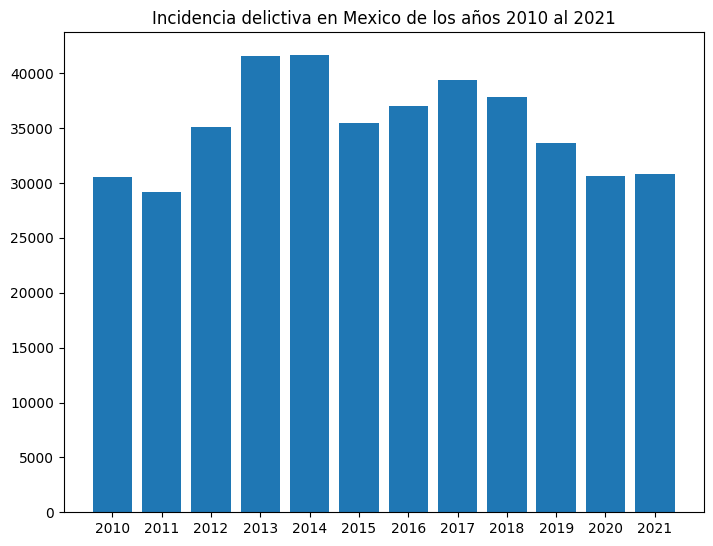

In [21]:
fig = plt.figure()
ax = fig.add_axes([0,0,1,1])
langs = ['2010','2011','2012','2013','2014','2015','2016','2017','2018','2019','2020','2021']
incidencia_delictiva = [30535, 29200, 35139, 41563, 41655, 35497, 37017, 39369, 37807, 33659, 30601, 30786]
ax.bar(langs,incidencia_delictiva)
ax.set_title('Incidencia delictiva en Mexico de los años 2010 al 2021')
plt.show()

Donde en referencia a la gráfica anterior se observa que en los años donde hubo mayor indice delictivo fue en el 2013, 2014 y 2017

Text(0.5, 1.0, 'Nivel de desempleo en Mexico de los años 2010 al 2021')

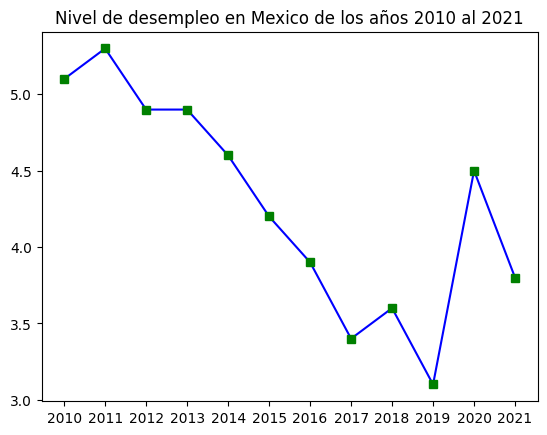

In [22]:
fig, ax = plt.subplots()
año = ['2010','2011','2012','2013','2014','2015','2016','2017','2018','2019','2020','2021']
tasa_desempleo = [5.1, 5.3, 4.9, 4.9, 4.6, 4.2, 3.9, 3.4, 3.6, 3.1, 4.5, 3.8]
ax.plot(año, tasa_desempleo, color = "b", marker = 's',
        markerfacecolor = 'green', markeredgecolor = 'green')
ax.set_title('Nivel de desempleo en Mexico de los años 2010 al 2021')

Observamos en esta gráfica anterior que los niveles de desempleo han tenido una tendencia descendente del año 2010 al 2017, ligeramente un repunte en el año 2018 y baja a su menor histórico en el año 2019 aunque aumenta más de 1% en el 2020.

Asi como también observamos en la siguiente tabla de descripción estadística de los datos, que existe una media considerable en cuanto a la incidencia delictiva incurrida en dicho periodo 2010-2021 con una tasa de desempleo medio.

In [24]:
df_incidencia_desempleo.describe().round(2)

,AÑO,INCIDENCIA DELICTIVA,TASA DE DESEMPLEO
count,12.00,12.00,12.00
mean,2015.50,35235.67,4.27
std,3.61,4374.32,0.72
min,2010.00,29200.00,3.10
25%,2012.75,30739.75,3.75
50%,2015.50,35318.00,4.35
75%,2018.25,38197.50,4.90
max,2021.00,41655.00,5.30


En la siguiente grafica vemos una vista preliminar entre la tasa o nivel de desempleo y la incidencia delictiva
donde se puede ver no muy fuerte dicha correlación entre ambos datos, pero seguiremos analizando aplicando dicha técnica
estadística.

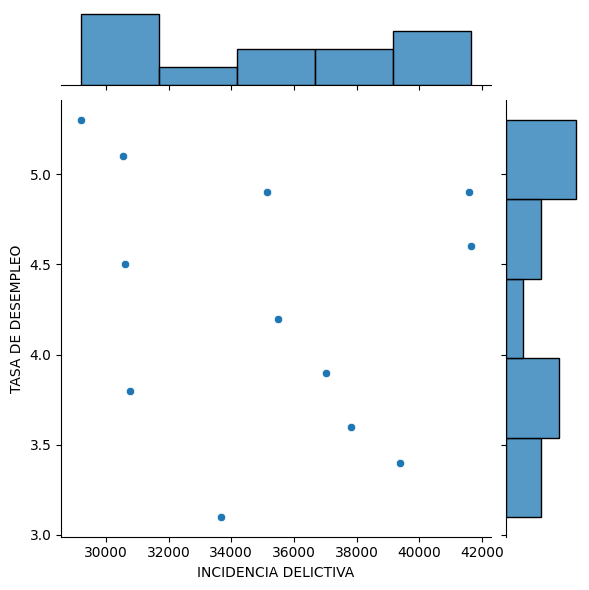

In [84]:
sns.jointplot(x='INCIDENCIA DELICTIVA',y='TASA DE DESEMPLEO', data=df_incidencia_desempleo)

3. APLICACION DE TÉCNICAS ESTADÍSTICAS: Para poder conocer el grado de correlacion de las variables mostradas 
anteriormente (incidencia delictiva y nivel de desempleo), se aplicará la técnica de análisis de regresión 
lineal y correlacion, con ello se explican los pasos para dicha aplicación:

In [87]:
# 1. División de los datos en train y test: Esto con el fin de estimar los parametros y el cálculo de errores

X = df_incidencia_desempleo[['AÑO', 'INCIDENCIA DELICTIVA']]
y = df_incidencia_desempleo['TASA DE DESEMPLEO']
X_train, X_test, y_train, y_test = train_test_split(
                                        X,
                                        y.values.reshape(-1,1),
                                        train_size   = 0.8,
                                        random_state = 1234,
                                        shuffle      = True)

In [88]:
# 2. Creación del modelo utilizando matrices: Con ello se va a visualizar la tabla de regresión con todos 
#    los datos correspondientes 

X_train = sm.add_constant(X_train, prepend=True)
modelo  = sm.OLS(endog=y_train, exog=X_train,)
modelo  = modelo.fit()
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.616
Model:                            OLS   Adj. R-squared:                  0.488
Method:                 Least Squares   F-statistic:                     4.812
Date:                Fri, 02 Jun 2023   Prob (F-statistic):             0.0566
Time:                        23:52:46   Log-Likelihood:                -4.5122
No. Observations:                   9   AIC:                             15.02
Df Residuals:                       6   BIC:                             15.62
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                  315.2749 

C:\Users\ravel\AppData\Local\Programs\Python\Python311\Lib\site-packages\scipy\stats\_stats_py.py:1736: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=9
  warnings.warn("kurtosistest only valid for n>=20 ... continuing "


In [82]:
# 3. Error de test del modelo: Con ello vamos a ver la cantidad de error 
#    que hay entre los dos conjuntos de datos que tratamos de inicio.

X_test = sm.add_constant(X_test, prepend=True)
predicciones = modelo.predict(exog = X_test)
rmse = mean_squared_error(
        y_true  = y_test,
        y_pred  = predicciones,
        squared = False
       )
print("")
print(f"El error (rmse) de test es: {rmse}")


El error (rmse) de test es: 2817.348695874868


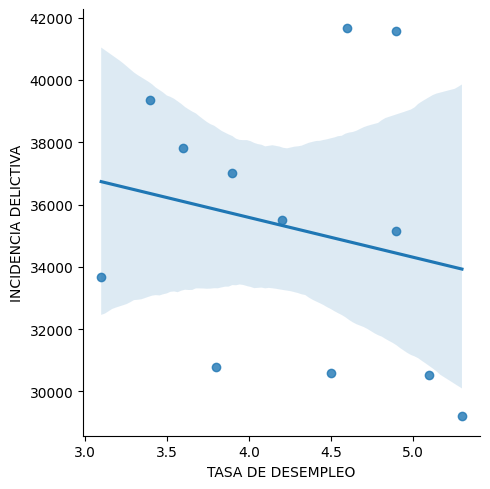

In [83]:
# 4. Gráfica del análisis de regresión lineal: Observamos la tendencia negativa de la pendiente con la debil relación
#    entre las variables

sns.lmplot(x='TASA DE DESEMPLEO',y='INCIDENCIA DELICTIVA', data=df_incidencia_desempleo)

4. INTERPRETACIÓN DE LOS RESULTADOS:
Analisis e interpretación los resultados obtenidos a partir de la técnica aplicada:

- Observando en la tabla del modelo de regresión lineal que el valor R-squared (0.6) su grado de variabilidad es media
- El valor de P o p-value la variable tasa de desempleo no tiene un efecto significativo, es decir, no afecta en nada al valor   de la variable incidencia delictiva.
- Se muestra tanto en los datos de la tabla del modelo de regresión como en la gráfica que la correlación entre ambas variables
  es debil o casi nula.

Conclusiones se pueden extraer y respuesta a la pregunta de investigación planteada en la primera parte:

- Se puede concluir a partir del analisis realizado que la relación de que haya un gran numero de incidencia delictiva si es     en parte, más no del todo por la falta de desempleo, ya que contribuyen mucho mas factores macro y microeconómicos en la       situación económica de un país, como es el nivel social o falta de recursos dependiendo del hábitat u origen de vivienda de     los habitantes de un país, asi como variables que son dificiles de controlar o regular como la corrupción y el nivel de         delincuencia surgido en cualquier diferente estrato social, que ello se ve aumentado o mermado en el grado de poder             adquisitivo y formas de adquisición de los bienes materiales que existe para cualquier habitante en el país.

Comparaciones, relaciones y proporcion de argumentos de respaldo por los resultados estadísticos.

- Como comparación se puede ver que en los datos de inicio entre la incidencia delictiva y la tasa de desempleo, es acerca
  de los tipos de datos ya que al ser unos enteros y los otros porcentajes en tendencia, provoca la poca relación entre dichas   variables.
- Los valores que pude conseguir acerca del nivel de desempleo en muchas paginas siempre los muestra por porcentajes
  y quiza la cantidad de datos a mostrar no es muy representativo.  

FUENTES OBTENIDAS PARA LA BASE DE DATOS PRINCIPAL:
    INEGI: https://www.inegi.org.mx/temas/incidencia/
    PROYECTOS MEXICO: https://www.proyectosmexico.gob.mx/por-que-invertir-en-mexico/mercado-potencial/sd_historico-tasa-de-desempleo-en-mexico/